In [1]:
import pandas as pd
import numpy as np

In [14]:
df = pd.read_parquet("prepared_dataset.parquet")

### Regression

Prediction of `PM2_5`

In [22]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from splitting import get_cv_splits


drop_cols = [
    'station_id', 'day',
    'pm2_5_corrected', 'aqi_category', 'is_health_risk', 'aqi_class',
    'target_1d', 'target_risk_1d', 'target_aqi_1d', 
    'target_2d', 'target_risk_2d', 'target_aqi_2d', 
    'target_3d', 'target_risk_3d', 'target_aqi_3d',
    'day_of_week', 'season'
]

# Separate features (X) from the dataset
feature_cols = [col for col in df.columns if col not in drop_cols]
X = df[feature_cols]

# Default hyperparameters specified for Task 3
params = {
    'n_estimators': 100,
    'max_depth': 6,
    'learning_rate': 0.1,
    'random_state': 42
}

cv_folds = get_cv_splits(df)

# Define the horizons we want to loop through
horizons = {
    't+1 (1-Day Ahead)': 'target_1d',
    't+2 (2-Day Ahead)': 'target_2d',
    't+3 (3-Day Ahead)': 'target_3d'
}

# Open a text file to save the final results summary
results_file = open("xgboost_horizon_results.txt", "w")
results_file.write("XGBoost Horizon Degradation Report\n" + "="*40 + "\n\n")

# Loop over each prediction horizon
for horizon_name, target_col in horizons.items():
    print(f"\n========================================")
    print(f" Training for Horizon: {horizon_name}")
    print(f"========================================")
    
    y = df[target_col]
    
    metrics_fold = {
        'rmse': [],
        'mae': [],
        'mape': [],
        'r2': []
    }
    
    for fold_idx, (train_idx, test_idx) in enumerate(cv_folds):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        # Initialize and train XGBoost Regressor
        model = xgb.XGBRegressor(**params)
        model.fit(X_train, y_train)
        
        # Predict on test set
        preds = model.predict(X_test)
        
        # Calculate metrics
        rmse = np.sqrt(mean_squared_error(y_test, preds))
        mae = mean_absolute_error(y_test, preds)
        mape = mean_absolute_percentage_error(y_test, preds)
        r2 = r2_score(y_test, preds)
        
        metrics_fold['rmse'].append(rmse)
        metrics_fold['mae'].append(mae)
        metrics_fold['mape'].append(mape)
        metrics_fold['r2'].append(r2)
        
        print(f"Fold {fold_idx+1} | RMSE: {rmse:.4f} | R2: {r2:.4f}")

    # Compute and print Mean ± Std across all 5 folds for this horizon
    print(f"\n--- Final CV Results for {horizon_name} ---")
    results_file.write(f"Horizon: {horizon_name}\n")
    
    for metric_name, values in metrics_fold.items():
        mean_val = np.mean(values)
        std_val = np.std(values)
        
        output_str = f"{metric_name.upper():<5}: {mean_val:.4f} +/- {std_val:.4f}"
        print(output_str)
        results_file.write(f"  {output_str}\n")
        
    results_file.write("-" * 40 + "\n")

results_file.close()
print("\n[INFO] All horizons completed! Results successfully saved to 'xgboost_horizon_results.txt'.")


 Training for Horizon: t+1 (1-Day Ahead)
Fold 1 | RMSE: 17.1950 | R2: 0.3539
Fold 2 | RMSE: 12.2577 | R2: 0.3319
Fold 3 | RMSE: 10.3309 | R2: 0.3348
Fold 4 | RMSE: 22.6126 | R2: 0.2971
Fold 5 | RMSE: 10.5806 | R2: 0.2934

--- Final CV Results for t+1 (1-Day Ahead) ---
RMSE : 14.5954 +/- 4.7075
MAE  : 10.6854 +/- 3.2103
MAPE : 0.2435 +/- 0.0368
R2   : 0.3222 +/- 0.0233

 Training for Horizon: t+2 (2-Day Ahead)
Fold 1 | RMSE: 19.1689 | R2: 0.1969
Fold 2 | RMSE: 13.9849 | R2: 0.1099
Fold 3 | RMSE: 11.8446 | R2: 0.1290
Fold 4 | RMSE: 26.1911 | R2: 0.0689
Fold 5 | RMSE: 11.2636 | R2: 0.0355

--- Final CV Results for t+2 (2-Day Ahead) ---
RMSE : 16.4906 +/- 5.5939
MAE  : 12.2452 +/- 3.8095
MAPE : 0.2802 +/- 0.0410
R2   : 0.1080 +/- 0.0550

 Training for Horizon: t+3 (3-Day Ahead)
Fold 1 | RMSE: 19.8017 | R2: 0.1411
Fold 2 | RMSE: 14.0835 | R2: 0.0902
Fold 3 | RMSE: 11.8444 | R2: 0.1335
Fold 4 | RMSE: 26.8366 | R2: 0.0235
Fold 5 | RMSE: 11.3529 | R2: -0.0713

--- Final CV Results for t+3 (3-

### Binary Classification

Prediction of `is_health_risk` flag

In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from splitting import get_cv_splits

drop_cols = [
    'station_id', 'day',
    'pm2_5_corrected', 'aqi_category', 'is_health_risk', 'aqi_class',
    'target_1d', 'target_risk_1d', 'target_aqi_1d', 
    'target_2d', 'target_risk_2d', 'target_aqi_2d', 
    'target_3d', 'target_risk_3d', 'target_aqi_3d',
    'day_of_week', 'season'
]

feature_cols = [col for col in df.columns if col not in drop_cols]
X = df[feature_cols]

cv_folds = get_cv_splits(df)

# Define the classification horizons we want to loop through
horizons = {
    't+1 Risk (1-Day Ahead)': 'target_risk_1d',
    't+2 Risk (2-Day Ahead)': 'target_risk_2d',
    't+3 Risk (3-Day Ahead)': 'target_risk_3d'
}

# Open a text file to save the final classification summary
results_file = open("xgboost_classification_results.txt", "w")
results_file.write("XGBoost Classification Horizon Report (Health Risk)\n" + "="*50 + "\n\n")

for horizon_name, target_col in horizons.items():
    print(f"\n========================================")
    print(f" Training Classification for: {horizon_name}")
    print(f"========================================")
    
    y = df[target_col]
    
    metrics_fold = {
        'precision': [],
        'recall': [],
        'f1': [],
        'auc_roc': []
    }
    
    for fold_idx, (train_idx, test_idx) in enumerate(cv_folds):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        # Calculate scale_pos_weight dynamically per fold
        n_negative = np.sum(y_train == 0)
        n_positive = np.sum(y_train == 1)
        pos_weight = n_negative / n_positive if n_positive > 0 else 1.0
        
        params = {
            'n_estimators': 100,
            'max_depth': 6,
            'learning_rate': 0.1,
            'scale_pos_weight': pos_weight,
            'random_state': 42,
            'eval_metric': 'logloss'
        }
        
        model = xgb.XGBClassifier(**params)
        model.fit(X_train, y_train)
        
        preds = model.predict(X_test)
        probs = model.predict_proba(X_test)[:, 1]
        
        prec = precision_score(y_test, preds, zero_division=0)
        rec = recall_score(y_test, preds, zero_division=0)
        f1 = f1_score(y_test, preds, zero_division=0)
        auc = roc_auc_score(y_test, probs)
        
        metrics_fold['precision'].append(prec)
        metrics_fold['recall'].append(rec)
        metrics_fold['f1'].append(f1)
        metrics_fold['auc_roc'].append(auc)
        
        print(f"Fold {fold_idx+1} | Pos Weight: {pos_weight:.2f} | Recall: {rec:.4f} | Precision: {prec:.4f} | AUC: {auc:.4f}")

    print(f"\n--- Final CV Results for {horizon_name} ---")
    results_file.write(f"Horizon: {horizon_name}\n")
    
    for metric_name, values in metrics_fold.items():
        mean_val = np.mean(values)
        std_val = np.std(values)
        output_str = f"{metric_name.upper():<10}: {mean_val:.4f} +/- {std_val:.4f}"
        print(output_str)
        results_file.write(f"  {output_str}\n")
        
    results_file.write("-" * 40 + "\n")

results_file.close()
print("\n[INFO] All classification horizons completed! Results saved to 'xgboost_classification_results.txt'.")


 Training Classification for: t+1 Risk (1-Day Ahead)
Fold 1 | Pos Weight: 3.69 | Recall: 0.6323 | Precision: 0.6157 | AUC: 0.7988
Fold 2 | Pos Weight: 3.15 | Recall: 0.4417 | Precision: 0.5196 | AUC: 0.8082
Fold 3 | Pos Weight: 3.36 | Recall: 0.3913 | Precision: 0.4426 | AUC: 0.8404
Fold 4 | Pos Weight: 3.80 | Recall: 0.5973 | Precision: 0.6312 | AUC: 0.7548
Fold 5 | Pos Weight: 3.16 | Recall: 0.1525 | Precision: 0.3600 | AUC: 0.7662

--- Final CV Results for t+1 Risk (1-Day Ahead) ---
PRECISION : 0.5138 +/- 0.1029
RECALL    : 0.4430 +/- 0.1713
F1        : 0.4690 +/- 0.1502
AUC_ROC   : 0.7937 +/- 0.0306

 Training Classification for: t+2 Risk (2-Day Ahead)
Fold 1 | Pos Weight: 3.71 | Recall: 0.6123 | Precision: 0.5516 | AUC: 0.7433
Fold 2 | Pos Weight: 3.14 | Recall: 0.1983 | Precision: 0.4423 | AUC: 0.6987
Fold 3 | Pos Weight: 3.37 | Recall: 0.1594 | Precision: 0.2683 | AUC: 0.7619
Fold 4 | Pos Weight: 3.81 | Recall: 0.4389 | Precision: 0.5451 | AUC: 0.6403
Fold 5 | Pos Weight: 3.15 

### Feature Importance Analysis 

 Training t+1 Model for Feature Importance

[INFO] Top 25 features saved to 'xgboost_top_features.txt'.
[INFO] Horizontal bar chart saved as 'xgboost_top_features.png'.


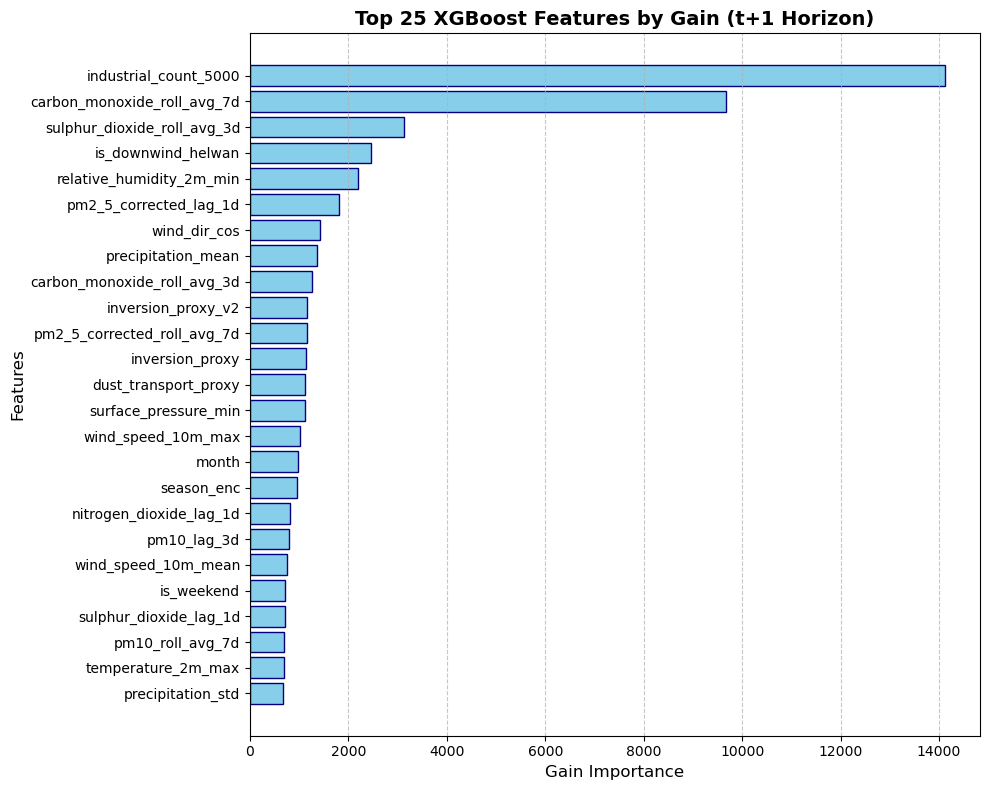


--- Verification of Key Physical Proxies ---
[is_downwind_helwan] -> Rank: 4 out of 80 | Gain Score: 2448.1787
[inversion_proxy_v2] -> Rank: 10 out of 80 | Gain Score: 1156.8259
[dust_transport_proxy] -> Rank: 13 out of 80 | Gain Score: 1118.8949


In [30]:
import matplotlib.pyplot as plt
from splitting import get_cv_splits


drop_cols = [
    'station_id', 'day',
    'pm2_5_corrected', 'aqi_category', 'is_health_risk', 'aqi_class',
    'target_1d', 'target_risk_1d', 'target_aqi_1d', 
    'target_2d', 'target_risk_2d', 'target_aqi_2d', 
    'target_3d', 'target_risk_3d', 'target_aqi_3d',
    'day_of_week', 'season'
]

feature_cols = [col for col in df.columns if col not in drop_cols]
X = df[feature_cols]
y = df['target_1d'] # t+1 regression target

cv_folds = get_cv_splits(df)

# Train on the first fold to extract feature importances
train_idx, test_idx = next(iter(cv_folds))
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]

params = {
    'n_estimators': 100,
    'max_depth': 6,
    'learning_rate': 0.1,
    'random_state': 42
}

print("========================================")
print(" Training t+1 Model for Feature Importance")
print("========================================")
model = xgb.XGBRegressor(**params)
model.fit(X_train, y_train)

# 2. Extract feature importances using 'gain'
importance_scores = model.get_booster().get_score(importance_type='gain')

# Convert to a clean DataFrame and sort
importance_df = pd.DataFrame({
    'feature': list(importance_scores.keys()),
    'gain': list(importance_scores.values())
}).sort_values(by='gain', ascending=False).reset_index(drop=True)

# Select Top 25 Features
top_25 = importance_df.head(25)

# Save tabular text report
with open("xgboost_top_features.txt", "w") as f:
    f.write("Top 25 Features by XGBoost Gain (t+1 Model)\n" + "="*50 + "\n\n")
    f.write(top_25.to_string(index=False))

print("\n[INFO] Top 25 features saved to 'xgboost_top_features.txt'.")

# 3. Generate Horizontal Bar Chart for Top 25 Features
plt.figure(figsize=(10, 8))

# Reverse the order so the highest importance appears at the top of the chart
top_25_sorted = top_25.iloc[::-1]

plt.barh(top_25_sorted['feature'], top_25_sorted['gain'], color='skyblue', edgecolor='navy')
plt.xlabel('Gain Importance', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Top 25 XGBoost Features by Gain (t+1 Horizon)', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

# Save the plot locally
plt.savefig('xgboost_top_features.png', dpi=300)
print("[INFO] Horizontal bar chart saved as 'xgboost_top_features.png'.")

plt.show()

# 4. Specific check for key physical proxy features
target_checks = ['is_downwind_helwan', 'inversion_proxy_v2', 'dust_transport_proxy']
print("\n--- Verification of Key Physical Proxies ---")
for feat in target_checks:
    if feat in importance_df['feature'].values:
        rank = importance_df[importance_df['feature'] == feat].index[0] + 1
        score = importance_df[importance_df['feature'] == feat]['gain'].values[0]
        print(f"[{feat}] -> Rank: {rank} out of {len(importance_df)} | Gain Score: {score:.4f}")
    else:
        print(f"[{feat}] -> Not found in the feature importance list.")